# 02 IMU audit

Audit of all 47 IMU text files from the three devices, before anything is paired or converted.

## Step 1 - setup and file list

Loads the config and the raw manifest and builds the list of IMU files. Nothing is written into raw.

In [1]:
import json
import warnings
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import yaml
from tqdm import tqdm

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)

# expected values, compared with the measurements later and never assumed
EXPECTED = {
    "rate_hz": 30.0,
    "rate_min_hz": 29.5,
    "rate_max_hz": 30.5,
    "chunk_rows": 5400,
    "chunk_s": 180,
    "chunks_per_device": 15,
    "full_chunks_per_device": 14,
    "n_files": 47,
    "n_stub": 2,
    "seam_factor": 1.5,
    "start_grid_max_ms": 100,
    "ctime_tol_s": 3,
    "first_start_offset_ms": 33.3,
}

DEVICES = ["head", "left", "right"]

# project root is the parent of the working directory
PROJECT_ROOT = Path.cwd().parent
config_path = PROJECT_ROOT / "configs" / "config.yaml"
if not config_path.exists():
    raise FileNotFoundError(
        f"configs/config.yaml not found under {PROJECT_ROOT}. "
        "Open this notebook from the notebooks folder of the project."
    )

with open(config_path, "r", encoding="utf-8") as fh:
    cfg = yaml.safe_load(fh)

def get_dir(name):
    d = cfg.get("directories", {})
    val = d.get(name, name) if isinstance(d, dict) else name
    return PROJECT_ROOT / (val if isinstance(val, str) else name)

RAW = get_dir("raw")
INTERIM = get_dir("interim")
REPORTS = get_dir("reports")
(INTERIM / "imu").mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)

CHUNK_S = cfg.get("chunk_seconds_hypothesis", EXPECTED["chunk_s"])
FPS = cfg.get("nominal_fps", EXPECTED["rate_hz"])
TOL_MS = float(cfg["thresholds"]["pairing_tolerance_ms"])

def show(df, n=50):
    print(df.head(n).to_string(index=False))
    if len(df) > n:
        print(f"... {len(df) - n} more rows not shown")

def rel_to_path(rel):
    return RAW.joinpath(*str(rel).replace("\\", "/").split("/"))

manifest_path = REPORTS / "raw_manifest.csv"
if not manifest_path.exists():
    raise FileNotFoundError(f"{manifest_path} not found, run notebook 01 first")

manifest = pd.read_csv(
    manifest_path,
    dtype={"rel_path": str, "device": str, "serial": str, "clip_no": str,
           "dup_suffix": str, "kind": str},
)
manifest["clip_no"] = pd.to_numeric(manifest["clip_no"], errors="coerce")
for col in ["src_modified_utc", "src_created_utc"]:
    manifest[col] = pd.to_datetime(manifest[col], utc=True, format="mixed", errors="coerce")

imu = manifest[manifest["kind"] == "imu"].copy()
imu["path"] = imu["rel_path"].map(rel_to_path)
imu["base_name"] = imu["path"].map(lambda p: p.stem)
imu["exists"] = imu["path"].map(lambda p: p.is_file())
imu["dev_order"] = imu["device"].map({d: i for i, d in enumerate(DEVICES)})
imu = imu.sort_values(["dev_order", "clip_no"])
imu_files = imu[["device", "serial", "clip_no", "base_name", "path", "exists"]].reset_index(drop=True)

print("project root:", PROJECT_ROOT)
print("imu files in manifest:", len(imu_files), "(expected", EXPECTED["n_files"], ")")
for d in DEVICES:
    sub = imu_files[imu_files["device"] == d]
    print(f"{d}: {len(sub)} files, {int(sub['exists'].sum())} found on disk")
missing = imu_files[~imu_files["exists"]]
if len(missing):
    print("missing on disk:", missing["base_name"].tolist())
if imu_files["base_name"].duplicated().any():
    print("warning: duplicate base names in the manifest")
on_disk = set(RAW.glob("*/VIDEO_CONVERTED/*.txt"))
extra = on_disk - set(imu_files["path"])
print("txt files on disk that are not in the manifest:", len(extra))

project root: c:\workstation\3RD YEAR\ego_pipeline
imu files in manifest: 47 (expected 47 )
head: 16 files, 16 found on disk
left: 15 files, 15 found on disk
right: 16 files, 16 found on disk
txt files on disk that are not in the manifest: 0


## Step 2 - parse every file

Reads each file line by line with json.loads and keeps the arrays of the good lines. Bad lines are counted, not dropped silently.

In [2]:
BOM = b"\xef\xbb\xbf"

def check_line(obj):
    # returns (t, acc, gyro) or None if the schema is wrong
    if not isinstance(obj, dict):
        return None
    if not all(k in obj for k in ("t_us", "acc", "gyro")):
        return None
    t = obj["t_us"]
    if isinstance(t, bool) or not isinstance(t, (int, float)):
        return None
    if isinstance(t, float) and not (np.isfinite(t) and t == int(t)):
        return None
    if abs(t) >= 2 ** 62:
        return None
    out = []
    for key in ("acc", "gyro"):
        v = obj[key]
        if not isinstance(v, list) or len(v) != 3:
            return None
        for x in v:
            if isinstance(x, bool) or not isinstance(x, (int, float)):
                return None
        out.append([float(x) for x in v])
    return int(t), out[0], out[1]

def line_ending_type(raw):
    crlf = raw.count(b"\r\n")
    lf = raw.count(b"\n") - crlf
    cr = raw.count(b"\r") - crlf
    if crlf and not lf and not cr:
        return "crlf"
    if lf and not crlf and not cr:
        return "lf"
    if cr and not crlf and not lf:
        return "cr"
    if not (crlf or lf or cr):
        return "none"
    return "mixed"

data = {}
info = []
out_dir = INTERIM / "imu"

for f in tqdm(list(imu_files.itertuples()), desc="parsing", mininterval=1.0):
    name = f.base_name
    rec = {"device": f.device, "clip_no": int(f.clip_no), "base_name": name,
           "n_lines": 0, "n_blank": 0, "n_parse_errors": 0, "n_bad_schema": 0,
           "bom": False, "line_ending": "none", "ends_with_newline": False,
           "read_error": ""}
    ts, accs, gyros = [], [], []
    try:
        raw = f.path.read_bytes()
        rec["bom"] = raw.startswith(BOM)
        rec["line_ending"] = line_ending_type(raw)
        rec["ends_with_newline"] = raw.endswith((b"\n", b"\r"))
        for i, ln in enumerate(raw.splitlines()):
            if i == 0 and ln.startswith(BOM):
                ln = ln[len(BOM):]
            rec["n_lines"] += 1
            s = ln.strip()
            if not s:
                rec["n_blank"] += 1
                continue
            try:
                obj = json.loads(s.decode("utf-8"))
            except ValueError:
                rec["n_parse_errors"] += 1
                continue
            try:
                got = check_line(obj)
            except Exception:
                got = None
            if got is None:
                rec["n_bad_schema"] += 1
                continue
            ts.append(got[0])
            accs.append(got[1])
            gyros.append(got[2])
    except Exception as e:
        rec["read_error"] = type(e).__name__
    t_arr = np.array(ts, dtype=np.int64)
    acc_arr = np.array(accs, dtype=np.float64).reshape(-1, 3)
    gyro_arr = np.array(gyros, dtype=np.float64).reshape(-1, 3)
    data[name] = {"t_us": t_arr, "acc": acc_arr, "gyro": gyro_arr}
    rec["n_good"] = len(t_arr)
    try:
        np.savez_compressed(out_dir / f"{name}.npz", t_us=t_arr, acc=acc_arr, gyro=gyro_arr)
    except Exception as e:
        rec["read_error"] = (rec["read_error"] + " npz:" + type(e).__name__).strip()
    info.append(rec)

parse_info = pd.DataFrame(info)
print("files parsed:", len(parse_info))
print("lines:", int(parse_info["n_lines"].sum()), " good rows:", int(parse_info["n_good"].sum()))
print("blank lines:", int(parse_info["n_blank"].sum()),
      " parse errors:", int(parse_info["n_parse_errors"].sum()),
      " bad schema:", int(parse_info["n_bad_schema"].sum()))
print("files with bom:", int(parse_info["bom"].sum()),
      " files without final newline:", int((~parse_info["ends_with_newline"]).sum()))
print("line endings:", parse_info["line_ending"].value_counts().to_dict())
problems = parse_info[(parse_info["n_parse_errors"] > 0) | (parse_info["n_bad_schema"] > 0)
                      | (parse_info["read_error"] != "")]
if len(problems):
    print("files with problems:")
    show(problems[["base_name", "n_lines", "n_parse_errors", "n_bad_schema", "read_error"]])
else:
    print("no file had parse errors, bad schema lines or read errors")

parsing: 100%|██████████| 47/47 [00:03<00:00, 12.17it/s]

files parsed: 47
lines: 230532  good rows: 230532
blank lines: 0  parse errors: 0  bad schema: 0
files with bom: 0  files without final newline: 0
line endings: {'lf': 47}
no file had parse errors, bad schema lines or read errors


## Step 3 - per file summary

One row per file with the timing, value and rest statistics. Saved to reports.

In [3]:
def longest_run(mask):
    if mask.size == 0 or not mask.any():
        return 0
    m = np.concatenate(([0], mask.astype(int), [0]))
    d = np.diff(m)
    return int((np.where(d == -1)[0] - np.where(d == 1)[0]).max())

def stat(fn, a):
    a = np.asarray(a, dtype=float)
    a = a[np.isfinite(a)]
    return float(fn(a)) if a.size else np.nan

cols = ["device", "clip_no", "base_name", "rows", "status", "first_t_us", "last_t_us",
        "span_s", "duration_s", "mean_rate_hz", "dt_min_ms", "dt_median_ms", "dt_p05_ms",
        "dt_p95_ms", "dt_max_ms", "n_dt_zero", "n_dt_negative", "n_dt_lt_10ms",
        "n_dt_gt_50ms", "n_dt_gt_100ms", "n_big_gaps", "n_repeated_acc_rows",
        "max_repeat_run", "n_all_zero_rows", "n_t_us_zero", "n_nan", "acc_norm_median",
        "gyro_norm_median", "gyro_norm_peak", "acc_min", "acc_max", "rest_norm",
        "rest_norm_std", "rest_dir_x", "rest_dir_y", "rest_dir_z",
        "rest_dir_cos_to_device_median"]
count_cols = ["n_dt_zero", "n_dt_negative", "n_dt_lt_10ms", "n_dt_gt_50ms", "n_dt_gt_100ms",
              "n_big_gaps", "n_repeated_acc_rows", "max_repeat_run", "n_all_zero_rows",
              "n_t_us_zero", "n_nan"]

recs = []
first_list, last_list = [], []
for f in imu_files.itertuples():
    name = f.base_name
    t = data[name]["t_us"]
    acc = data[name]["acc"]
    gyro = data[name]["gyro"]
    n = len(t)
    r = dict.fromkeys(cols, np.nan)
    for c in count_cols:
        r[c] = 0
    r.update({"device": f.device, "clip_no": int(f.clip_no), "base_name": name, "rows": n})

    zero_row = np.all(acc == 0, axis=1) & np.all(gyro == 0, axis=1)
    if n == 0:
        status = "empty"
    elif zero_row.all() or (t == 0).all():
        status = "stub"
    elif n < EXPECTED["chunk_rows"]:
        status = "partial"
    elif n == EXPECTED["chunk_rows"]:
        status = "full"
    else:
        status = "other"
    r["status"] = status
    r["n_all_zero_rows"] = int(zero_row.sum())
    r["n_t_us_zero"] = int((t == 0).sum())
    r["n_nan"] = int(np.isnan(acc).sum() + np.isnan(gyro).sum())

    first_list.append(int(t[0]) if n else None)
    last_list.append(int(t[-1]) if n else None)

    if n >= 2:
        dt = np.diff(t)
        dt_ms = dt / 1000.0
        med = float(np.median(dt))
        span = (int(t[-1]) - int(t[0])) / 1e6
        r["span_s"] = span
        r["duration_s"] = span + med / 1e6
        r["mean_rate_hz"] = (n - 1) / span if span > 0 else np.nan
        r["dt_min_ms"] = float(dt_ms.min())
        r["dt_median_ms"] = med / 1000.0
        r["dt_p05_ms"], r["dt_p95_ms"] = [float(x) for x in np.percentile(dt_ms, [5, 95])]
        r["dt_max_ms"] = float(dt_ms.max())
        r["n_dt_zero"] = int((dt == 0).sum())
        r["n_dt_negative"] = int((dt < 0).sum())
        r["n_dt_lt_10ms"] = int((dt_ms < 10).sum())    # includes zero and negative
        r["n_dt_gt_50ms"] = int((dt_ms > 50).sum())
        r["n_dt_gt_100ms"] = int((dt_ms > 100).sum())
        r["n_big_gaps"] = int((dt > 2 * med).sum())
        same = np.all(acc[1:] == acc[:-1], axis=1)
        r["n_repeated_acc_rows"] = int(same.sum())
        r["max_repeat_run"] = longest_run(same)     # longest streak of repeated rows

    if n >= 1:
        anorm = np.linalg.norm(acc, axis=1)
        gnorm = np.linalg.norm(gyro, axis=1)
        r["acc_norm_median"] = stat(np.median, anorm)
        r["gyro_norm_median"] = stat(np.median, gnorm)
        r["gyro_norm_peak"] = stat(np.max, gnorm)
        r["acc_min"] = stat(np.min, acc.ravel())
        r["acc_max"] = stat(np.max, acc.ravel())
        if n >= 100:
            g = gnorm.copy()
            g[~np.isfinite(g)] = np.inf
            k = max(1, int(round(0.1 * n)))
            idx = np.argsort(g, kind="stable")[:k]
            ra = acc[idx]
            rnorm = np.linalg.norm(ra, axis=1)
            r["rest_norm"] = stat(np.mean, rnorm)
            r["rest_norm_std"] = stat(np.std, rnorm)
            m = np.nanmean(ra, axis=0)
            mn = np.linalg.norm(m)
            if np.isfinite(mn) and mn > 0:
                r["rest_dir_x"], r["rest_dir_y"], r["rest_dir_z"] = (m / mn).tolist()
    recs.append(r)

summary = pd.DataFrame(recs)[cols]
summary["first_t_us"] = pd.Series(first_list, dtype="Int64", index=summary.index)
summary["last_t_us"] = pd.Series(last_list, dtype="Int64", index=summary.index)

# cosine to the median rest direction of the same device
dir_cols = ["rest_dir_x", "rest_dir_y", "rest_dir_z"]
ok_status = summary["status"].isin(["partial", "full", "other"])
for d in DEVICES:
    sel = (summary["device"] == d) & ok_status & summary[dir_cols].notna().all(axis=1)
    if sel.sum() == 0:
        continue
    med_dir = np.nanmedian(summary.loc[sel, dir_cols].to_numpy(), axis=0)
    nm = np.linalg.norm(med_dir)
    if nm == 0:
        continue
    med_dir = med_dir / nm
    dev_rows = (summary["device"] == d) & summary[dir_cols].notna().all(axis=1)
    summary.loc[dev_rows, "rest_dir_cos_to_device_median"] = summary.loc[dev_rows, dir_cols].to_numpy() @ med_dir

summary.to_csv(REPORTS / "02_imu_file_summary.csv", index=False)

show(summary[["device", "clip_no", "rows", "status", "span_s", "mean_rate_hz"]].round(3))
print("status counts:", summary["status"].value_counts().to_dict())

flip = summary[summary["rest_dir_cos_to_device_median"] < 0.5]
print()
if len(flip):
    print("possible orientation change:")
    show(flip[["device", "clip_no", "base_name", "rest_dir_cos_to_device_median"]].round(3))
else:
    print("possible orientation change: none (all cosines >= 0.5 or not defined)")

device  clip_no  rows  status  span_s  mean_rate_hz
  head       36  5400    full 179.984        29.997
  head       37  5400    full 179.956        30.002
  head       38  5400    full 179.992        29.996
  head       39  5400    full 179.954        30.002
  head       40  5400    full 179.981        29.998
  head       41  5400    full 179.953        30.002
  head       42  5400    full 179.983        29.997
  head       43  5400    full 179.953        30.002
  head       44  5400    full 179.990        29.996
  head       45  5400    full 179.954        30.002
  head       46  5400    full 179.985        29.997
  head       47  5400    full 179.959        30.001
  head       48  5400    full 179.951        30.003
  head       49  5400    full 179.986        29.997
  head       50  1771 partial  59.006        29.997
  head       51    16    stub   0.000           NaN
  left       20  5400    full 179.954        30.002
  left       21  5400    full 179.950        30.003
  left      

## Step 4 - stub files

Looks at the files with status stub. They are put aside and left out of all later steps.

In [4]:
stub_rows = []
for s in summary[summary["status"] == "stub"].itertuples():
    d = data[s.base_name]
    all_zero = bool(np.all(d["acc"] == 0) and np.all(d["gyro"] == 0))
    any_t = bool((d["t_us"] != 0).any())
    stub_rows.append({"base_name": s.base_name, "rows": s.rows,
                      "all_values_zero": all_zero, "any_t_us_nonzero": any_t})
stub_check = pd.DataFrame(stub_rows, columns=["base_name", "rows", "all_values_zero", "any_t_us_nonzero"])

if len(stub_check):
    show(stub_check)
else:
    print("no stub files found")

quarantined = stub_check["base_name"].tolist()
print("quarantined:", quarantined)

empty_files = summary[summary["status"] == "empty"]["base_name"].tolist()
if empty_files:
    print("files with no good rows (also left out):", empty_files)

use = summary[summary["status"].isin(["partial", "full", "other"])].copy()
use = use.sort_values(["device", "clip_no"]).reset_index(drop=True)
print("files used from here on:", len(use))

    base_name  rows  all_values_zero  any_t_us_nonzero
a45140-H-0051    16             True             False
a59879-H-0041     9             True             False
quarantined: ['a45140-H-0051', 'a59879-H-0041']
files used from here on: 45


## Step 5 - chunk structure

Checks the rows per chunk, the gaps at the seams between chunks and how far each chunk start is from a 180 s grid.

In [5]:
chunk_rows = []
seam_rows = []
for d in DEVICES:
    g = use[use["device"] == d].sort_values("clip_no").reset_index(drop=True)
    if g.empty:
        print(d, "no chunks")
        continue
    first0 = int(g.loc[0, "first_t_us"])
    for k, row in enumerate(g.itertuples(), start=1):
        err = ((int(row.first_t_us) - first0) - (k - 1) * CHUNK_S * 1_000_000) / 1000.0
        chunk_rows.append({"device": d, "k": k, "clip_no": row.clip_no, "base_name": row.base_name,
                           "rows": row.rows, "duration_s": row.duration_s,
                           "first_t_us": int(row.first_t_us), "last_t_us": int(row.last_t_us),
                           "start_grid_error_ms": err, "rest_norm": row.rest_norm,
                           "rest_dir_z": row.rest_dir_z})
    ch = [c for c in chunk_rows if c["device"] == d]
    for a, b in zip(ch[:-1], ch[1:]):
        seam_rows.append({"device": d, "chunk_k": b["k"], "clip_prev": a["clip_no"],
                          "clip_next": b["clip_no"],
                          "seam_gap_ms": (b["first_t_us"] - a["last_t_us"]) / 1000.0,
                          "start_grid_error_ms": b["start_grid_error_ms"]})

    full = g["rows"] == EXPECTED["chunk_rows"]
    print(f"{d}: {len(g)} chunks, {int(full.sum())} with exactly {EXPECTED['chunk_rows']} rows")
    print("  rows per chunk:", g["rows"].tolist())
    odd = g[~full]
    print("  not full:", [f"{int(c)}:{int(r)}" for c, r in zip(odd["clip_no"], odd["rows"])])
    print(f"  last chunk duration: {g['duration_s'].iloc[-1]:.2f} s")
    jumps = np.diff(g["clip_no"].to_numpy())
    if (jumps != 1).any():
        print("  clip numbers are not consecutive:", g["clip_no"].tolist())

chunks = pd.DataFrame(chunk_rows)
seams = pd.DataFrame(seam_rows)
seams.to_csv(REPORTS / "02_seams.csv", index=False)

pooled_dt = np.concatenate([np.diff(data[n]["t_us"]) for n in use["base_name"]]) / 1000.0
median_dt_ms = float(np.median(pooled_dt))
print(f"\nmedian interval over all used files: {median_dt_ms:.3f} ms")

print("\nseams (start grid error is for the later chunk):")
st = seams.assign(abs_gap=seams["seam_gap_ms"].abs(), abs_grid=seams["start_grid_error_ms"].abs())
stats = st.groupby("device").agg(n_seams=("abs_gap", "size"),
                                 gap_median_ms=("abs_gap", "median"), gap_max_ms=("abs_gap", "max"),
                                 grid_median_ms=("abs_grid", "median"), grid_max_ms=("abs_grid", "max"))
print(stats.round(3).to_string())

head: 15 chunks, 14 with exactly 5400 rows
  rows per chunk: [5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 1771]
  not full: ['50:1771']
  last chunk duration: 59.04 s
left: 15 chunks, 14 with exactly 5400 rows
  rows per chunk: [5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 654]
  not full: ['34:654']
  last chunk duration: 21.79 s
right: 15 chunks, 14 with exactly 5400 rows
  rows per chunk: [5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 1282]
  not full: ['40:1282']
  last chunk duration: 42.75 s

median interval over all used files: 34.036 ms

seams (start grid error is for the later chunk):
        n_seams  gap_median_ms  gap_max_ms  grid_median_ms  grid_max_ms
device                                                                 
head         14         32.109      34.574          19.507       30.171
left         14         34.089      35.241          20.142       3

## Step 6 - file date cross-check

Compares the creation times from the manifest with the durations from the IMU data. File-system dates are only a hint.

In [6]:
def hms(td):
    if pd.isna(td):
        return "n/a"
    s = int(round(td.total_seconds()))
    sign = "-" if s < 0 else ""
    s = abs(s)
    return f"{sign}{s // 3600}:{s % 3600 // 60:02d}:{s % 60:02d}"

def with_gaps(df):
    parts = []
    for d in DEVICES:
        x = df[df["device"] == d].sort_values("clip_no").copy()
        x["gap_prev_s"] = x["src_created_utc"].diff().dt.total_seconds()
        parts.append(x)
    return pd.concat(parts, ignore_index=True)

dup_empty = manifest["dup_suffix"].fillna("").astype(str).str.strip() == ""
txt = with_gaps(manifest[manifest["kind"] == "imu"])
vid = with_gaps(manifest[(manifest["kind"] == "video") & dup_empty])
for df in (txt, vid):
    df["base_name"] = df["rel_path"].map(lambda p: rel_to_path(p).stem)

dur_map = summary.set_index("base_name")["duration_s"]
status_map = summary.set_index("base_name")["status"]
txt["status"] = txt["base_name"].map(status_map)
txt["duration_s_imu"] = txt["base_name"].map(dur_map)
txt["gap_minus_duration_s"] = txt["gap_prev_s"] - txt["duration_s_imu"]
vid["status"] = ""
vid["duration_s_imu"] = np.nan
vid["gap_minus_duration_s"] = np.nan

def report_dates(df, label):
    print(label)
    firsts = {}
    for d in DEVICES:
        x = df[df["device"] == d]
        if x.empty:
            continue
        firsts[d] = x["src_created_utc"].iloc[0]
        print(f"  {d}: first {x['src_created_utc'].iloc[0]}  last {x['src_created_utc'].iloc[-1]}  files {len(x)}")
        print("    gaps (s):", [round(v, 1) for v in x["gap_prev_s"].dropna().tolist()])
    if "head" in firsts:
        for d in ("left", "right"):
            if d in firsts:
                print(f"  first created, head - {d}: {hms(firsts['head'] - firsts[d])}")

report_dates(txt, "imu txt files (stubs included)")
print()
report_dates(vid, "mp4 files (no duplicates)")

keep = ["device", "clip_no", "base_name", "kind", "status", "src_created_utc", "src_modified_utc",
        "gap_prev_s", "duration_s_imu", "gap_minus_duration_s"]
time_check = pd.concat([txt[keep], vid[keep]], ignore_index=True)
time_check.to_csv(REPORTS / "02_file_time_check.csv", index=False)

print("\ncreation gap to the previous file vs duration of the file from imu data:")
side = txt[txt["status"].isin(["partial", "full", "other"]) & txt["gap_prev_s"].notna()]
side = side[["device", "clip_no", "gap_prev_s", "duration_s_imu", "gap_minus_duration_s"]]
show(side.round(2))
print("\nnote: file-system dates are only a hint and not capture time.")

imu txt files (stubs included)
  head: first 2026-07-06 02:47:12+00:00  last 2026-07-06 03:27:14+00:00  files 16
    gaps (s): [180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 60.0, 2.0]
  left: first 2026-07-06 19:00:22+00:00  last 2026-07-06 19:39:44+00:00  files 15
    gaps (s): [180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 22.0]
  right: first 2026-07-06 18:01:06+00:00  last 2026-07-06 18:40:52+00:00  files 16
    gaps (s): [180.0, 182.0, 178.0, 182.0, 180.0, 178.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 180.0, 44.0, 2.0]
  first created, head - left: -16:13:10
  first created, head - right: -15:13:54

mp4 files (no duplicates)
  head: first 2026-10-11 03:38:42+00:00  last 2026-10-11 03:42:06+00:00  files 15
    gaps (s): [14.0, 14.0, 18.0, 16.0, 16.0, 12.0, 16.0, 16.0, 16.0, 14.0, 14.0, 20.0, 14.0, 4.0]
  left: first 2026-10-11 03:29:48+00:00  last 2026-10-11 03:35:56+00:00  files 15
    ga

## Step 7 - triplet check

Lines up the clips of the three devices by rank and compares their start and end times on the IMU clock only.

In [7]:
per = {d: use[use["device"] == d].sort_values("clip_no").reset_index(drop=True) for d in DEVICES}
counts = {d: len(per[d]) for d in DEVICES}
n_rank = min(counts.values())
print("non-stub clips per device:", counts, "-> ranks used:", n_rank)

trip_rows = []
for i in range(n_rank):
    h, l, r = per["head"].iloc[i], per["left"].iloc[i], per["right"].iloc[i]
    firsts = [int(h.first_t_us), int(l.first_t_us), int(r.first_t_us)]
    lasts = [int(h.last_t_us), int(l.last_t_us), int(r.last_t_us)]
    row = {"rank": i + 1,
           "head_clip": h.clip_no, "left_clip": l.clip_no, "right_clip": r.clip_no,
           "head_first_t_us": firsts[0], "left_first_t_us": firsts[1], "right_first_t_us": firsts[2],
           "start_offset_left_ms": (firsts[1] - firsts[0]) / 1000.0,
           "start_offset_right_ms": (firsts[2] - firsts[0]) / 1000.0,
           "head_last_t_us": lasts[0], "left_last_t_us": lasts[1], "right_last_t_us": lasts[2],
           "end_offset_left_ms": (lasts[1] - lasts[0]) / 1000.0,
           "end_offset_right_ms": (lasts[2] - lasts[0]) / 1000.0,
           "head_duration_s": h.duration_s, "left_duration_s": l.duration_s,
           "right_duration_s": r.duration_s,
           "overlap_s": max(0.0, (min(lasts) - max(firsts)) / 1e6)}
    row["flag"] = bool(abs(row["start_offset_left_ms"]) > TOL_MS or abs(row["start_offset_right_ms"]) > TOL_MS)
    trip_rows.append(row)

triplets = pd.DataFrame(trip_rows)
triplets.to_csv(REPORTS / "02_triplet_offsets.csv", index=False)

show(triplets[["rank", "head_clip", "left_clip", "right_clip", "start_offset_left_ms",
               "start_offset_right_ms", "end_offset_left_ms", "end_offset_right_ms",
               "overlap_s", "flag"]].round(2))
print(f"\ntolerance from config: {TOL_MS} ms, flagged triplets: {int(triplets['flag'].sum())}")

if len(triplets) >= 3:
    for side_name in ("left", "right"):
        slope, icpt = np.polyfit(triplets["rank"], triplets[f"start_offset_{side_name}_ms"], 1)
        ppm = slope / (CHUNK_S * 1000.0) * 1e6
        print(f"{side_name}: slope {slope:.3f} ms per rank = {ppm:.1f} ppm of {CHUNK_S} s")
    print(f"this is a rough check with only {len(triplets)} points.")
else:
    print("not enough triplets for a line fit")

non-stub clips per device: {'head': 15, 'left': 15, 'right': 15} -> ranks used: 15
 rank  head_clip  left_clip  right_clip  start_offset_left_ms  start_offset_right_ms  end_offset_left_ms  end_offset_right_ms  overlap_s  flag
    1         36         20          26                -34.25                 -30.11              -64.28               -62.62     179.92 False
    2         37         21          27                -63.96                 -62.07              -70.40               -66.13     179.89 False
    3         38         22          28                -63.56                 -64.06              -69.28               -72.29     179.92 False
    4         39         23          29                -66.88                 -67.33              -36.44               -67.73     179.89 False
    5         40         24          30                -35.17                 -74.45              -30.73               -34.03     179.95 False
    6         41         25          31                -33.

## Step 8 - timing outliers

Pools every interval of the used files and looks at the shares per size and at the extreme values.

In [8]:
parts = []
for name in use["base_name"]:
    t = data[name]["t_us"]
    if len(t) < 2:
        continue
    parts.append(pd.DataFrame({"file": name, "row_index": np.arange(1, len(t)),
                               "t_us": t[1:], "dt_ms": np.diff(t) / 1000.0}))
pooled = pd.concat(parts, ignore_index=True)    # row_index is the later row of the interval

edges = [-np.inf, 20, 30, 40, 50, 100, np.inf]
labels = ["below 20", "20 to 30", "30 to 40", "40 to 50", "50 to 100", "100 and above"]
binned = pd.cut(pooled["dt_ms"], bins=edges, labels=labels, right=False)
bin_counts = binned.value_counts().reindex(labels)
bin_table = pd.DataFrame({"bin_ms": labels, "count": bin_counts.to_numpy(),
                          "share_pct": (bin_counts.to_numpy() / len(pooled) * 100)})
print("intervals pooled:", len(pooled))
print(bin_table.round(3).to_string(index=False))

largest = pooled.nlargest(40, "dt_ms").assign(which="largest")
smallest = pooled.nsmallest(40, "dt_ms").assign(which="smallest")
outliers = pd.concat([largest, smallest], ignore_index=True)
outliers.to_csv(REPORTS / "02_dt_outliers.csv", index=False)
print(f"\nlargest {pooled['dt_ms'].max():.3f} ms, smallest {pooled['dt_ms'].min():.3f} ms")

zero_dt = pooled[pooled["dt_ms"] <= 0]
print(f"\nintervals with dt <= 0: {len(zero_dt)}")
if len(zero_dt):
    show(zero_dt[["file", "row_index", "t_us", "dt_ms"]])

intervals pooled: 230462
       bin_ms  count  share_pct
     below 20     13      0.006
     20 to 30  32574     14.134
     30 to 40 197675     85.773
     40 to 50     84      0.036
    50 to 100    114      0.049
100 and above      2      0.001

largest 124.172 ms, smallest 0.000 ms

intervals with dt <= 0: 6
         file  row_index       t_us  dt_ms
a45140-H-0049         11 2348147768    0.0
a45140-H-0049         12 2348147768    0.0
a45140-H-0050         10 2528151685    0.0
a45140-H-0050         11 2528151685    0.0
a60617-H-0032        624 2188544788    0.0
a59879-H-0039         12 2348193771    0.0


## Step 9 - hypothesis checks

Each expected value is tested against what was measured. The result is PASS, FLAG or INFO when a test cannot be computed.

In [9]:
tests = []

def add_test(tid, hyp, fn):
    try:
        measured, ok = fn()
        result = "INFO" if ok is None else ("PASS" if ok else "FLAG")
    except Exception as e:
        measured, result = f"could not compute ({type(e).__name__})", "INFO"
    tests.append({"id": tid, "hypothesis": hyp, "measured": measured, "result": result})

def t1():
    pe = int(parse_info["n_parse_errors"].sum())
    bs = int(parse_info["n_bad_schema"].sum())
    re_ = int((parse_info["read_error"] != "").sum())
    files = int(((parse_info["n_parse_errors"] > 0) | (parse_info["n_bad_schema"] > 0)).sum())
    return f"parse errors {pe}, bad schema {bs}, read errors {re_}, files affected {files}", (pe == 0 and bs == 0 and re_ == 0)

def t2():
    stubs = summary[summary["status"] == "stub"]["base_name"].tolist()
    zero_t = summary[summary["n_t_us_zero"] > 0]["base_name"].tolist()
    stubs_ok = (len(stub_check) > 0 and bool(stub_check["all_values_zero"].all())
                and not bool(stub_check["any_t_us_nonzero"].any()))
    only = set(zero_t) == set(stubs)
    ok = stubs_ok and only and len(stubs) == EXPECTED["n_stub"]
    return (f"stubs {len(stubs)} (expected {EXPECTED['n_stub']}), all zero and t_us 0: {stubs_ok}, "
            f"files with t_us = 0: {len(zero_t)}, only stubs: {only}"), ok

def t3():
    r = use["mean_rate_hz"]
    bad = use[~((r >= EXPECTED["rate_min_hz"]) & (r <= EXPECTED["rate_max_hz"]))]
    txt_bad = bad["base_name"].tolist()[:6]
    return f"min {r.min():.3f} Hz, max {r.max():.3f} Hz, outside range: {len(bad)} {txt_bad}", len(bad) == 0

def t4():
    parts_ = []
    ok_all = True
    exc = []
    for d in DEVICES:
        g = use[use["device"] == d].sort_values("clip_no")
        nfull = int((g["rows"] == EXPECTED["chunk_rows"]).sum())
        parts_.append(f"{d} {nfull}")
        ok_all = ok_all and nfull == EXPECTED["full_chunks_per_device"]
        exc += [f"{int(c)}:{int(r)}" for c, r in zip(g["clip_no"].iloc[:-1], g["rows"].iloc[:-1])
                if r != EXPECTED["chunk_rows"]]
    return (f"full chunks {', '.join(parts_)} (expected {EXPECTED['full_chunks_per_device']} each), "
            f"non-last exceptions: {exc if exc else 'none'}"), ok_all

def t5():
    limit = EXPECTED["seam_factor"] * median_dt_ms
    bad = seams[seams["seam_gap_ms"] >= limit]
    return (f"max seam gap {seams['seam_gap_ms'].max():.2f} ms, min {seams['seam_gap_ms'].min():.2f} ms, "
            f"limit {limit:.2f} ms, above limit {len(bad)}"), len(bad) == 0

def t6():
    mx = float(chunks["start_grid_error_ms"].abs().max())
    return f"max start grid error {mx:.2f} ms (limit {EXPECTED['start_grid_max_ms']} ms)", mx < EXPECTED["start_grid_max_ms"]

def t7():
    mx = float(triplets[["start_offset_left_ms", "start_offset_right_ms"]].abs().max().max())
    nf = int(triplets["flag"].sum())
    return f"max start offset {mx:.2f} ms, tolerance {TOL_MS} ms, flagged triplets {nf}", nf == 0

def t8():
    nz = int((pooled["dt_ms"] == 0).sum())
    nn = int((pooled["dt_ms"] < 0).sum())
    nfiles = pooled[pooled["dt_ms"] <= 0]["file"].nunique()
    return f"zero {nz}, negative {nn}, files affected {nfiles}", (nz + nn) == 0

def t9():
    bad = []
    worst = 0.0
    n = 0
    for d in DEVICES:
        x = txt[(txt["device"] == d) & txt["status"].isin(["partial", "full", "other"])]
        x = x.sort_values("clip_no")
        gaps = x["gap_prev_s"].iloc[1:-1].dropna()
        for c, gp in zip(x["clip_no"].iloc[1:-1], x["gap_prev_s"].iloc[1:-1]):
            n += 1
            dev = abs(gp - CHUNK_S)
            worst = max(worst, dev) if np.isfinite(dev) else worst
            if not (dev <= EXPECTED["ctime_tol_s"]):
                bad.append(f"{d}{int(c)}")
    return f"{n} gaps checked, max |gap - {CHUNK_S}| {worst:.2f} s, outside tolerance {len(bad)} {bad[:6]}", len(bad) == 0

def t10():
    parts_ = []
    ok_all = True
    for d in DEVICES:
        g = use[use["device"] == d].sort_values("clip_no")
        last = g.iloc[-1]
        parts_.append(f"{d} {last['duration_s']:.1f} s")
        ok_all = ok_all and bool(last["duration_s"] < CHUNK_S)
    return "last chunk duration: " + ", ".join(parts_), ok_all

add_test("T1", "no parse errors or bad schema lines in any file", t1)
add_test("T2", "stub files are all zero with t_us = 0 and the only files with t_us = 0", t2)
add_test("T3", "mean rate between 29.5 and 30.5 Hz for every used file", t3)
add_test("T4", "all chunks except the last have exactly 5400 rows", t4)
add_test("T5", "every seam gap is below 1.5 x the median interval", t5)
add_test("T6", "chunk starts stay within 100 ms of a 180 s grid", t6)
add_test("T7", "every triplet start offset is within the pairing tolerance", t7)
add_test("T8", "no interval with dt <= 0", t8)
add_test("T9", "txt creation time gaps equal 180 s except the last chunk", t9)
add_test("T10", "the last chunk of each device is shorter than 180 s", t10)

hyp = pd.DataFrame(tests)
hyp.to_csv(REPORTS / "02_hypothesis_check.csv", index=False)
for row in hyp.itertuples():
    print(f"{row.id:<4} {row.result:<5} {row.hypothesis}")
    print(f"           {row.measured}")
print("\npass:", int((hyp['result'] == 'PASS').sum()), " flag:", int((hyp['result'] == 'FLAG').sum()),
      " info:", int((hyp['result'] == 'INFO').sum()))

T1   PASS  no parse errors or bad schema lines in any file
           parse errors 0, bad schema 0, read errors 0, files affected 0
T2   PASS  stub files are all zero with t_us = 0 and the only files with t_us = 0
           stubs 2 (expected 2), all zero and t_us 0: True, files with t_us = 0: 2, only stubs: True
T3   PASS  mean rate between 29.5 and 30.5 Hz for every used file
           min 29.990 Hz, max 30.012 Hz, outside range: 0 []
T4   PASS  all chunks except the last have exactly 5400 rows
           full chunks head 14, left 14, right 14 (expected 14 each), non-last exceptions: none
T5   PASS  every seam gap is below 1.5 x the median interval
           max seam gap 36.44 ms, min 25.95 ms, limit 51.05 ms, above limit 0
T6   PASS  chunk starts stay within 100 ms of a 180 s grid
           max start grid error 65.83 ms (limit 100 ms)
T7   PASS  every triplet start offset is within the pairing tolerance
           max start offset 74.45 ms, tolerance 100.0 ms, flagged triplets 0


## Step 10 - figures

Two figures: the layout of the chunks on the session clock and four quality panels.

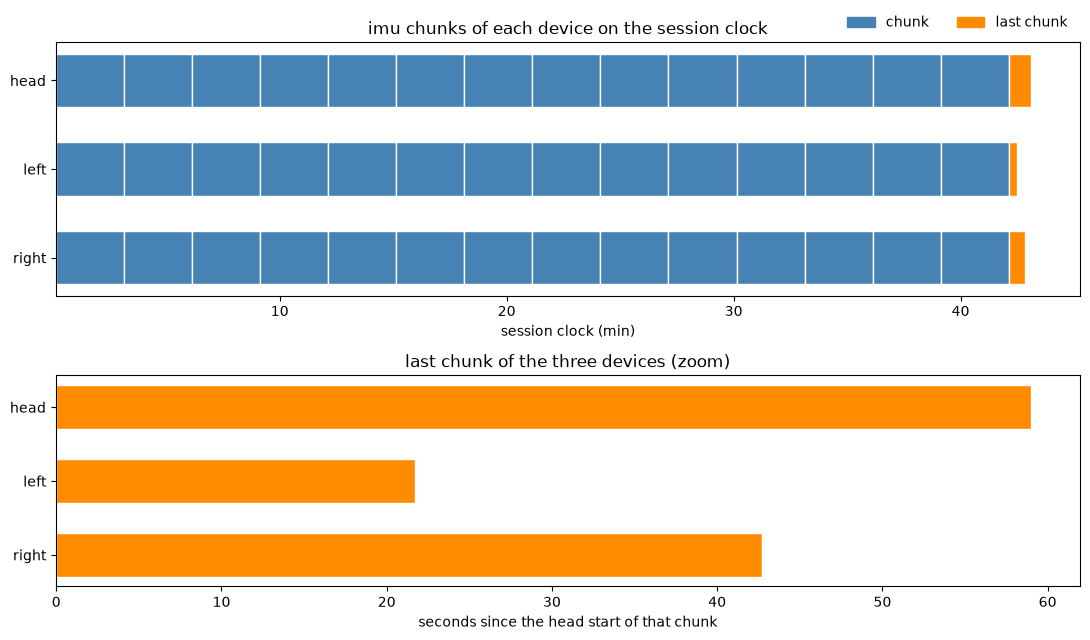

In [10]:
last_color, chunk_color = "darkorange", "steelblue"

fig = plt.figure(figsize=(11, 6.5))
gs = fig.add_gridspec(2, 1, height_ratios=[1.2, 1])
ax1 = fig.add_subplot(gs[0])
ax2 = fig.add_subplot(gs[1])

for yi, d in enumerate(DEVICES):
    g = chunks[chunks["device"] == d]
    for i, row in enumerate(g.itertuples()):
        start = row.first_t_us / 6e7
        width = (row.last_t_us - row.first_t_us) / 6e7
        c = last_color if i == len(g) - 1 else chunk_color
        ax1.barh(yi, width, left=start, height=0.6, color=c, edgecolor="white", linewidth=1.0)
ax1.set_yticks(range(len(DEVICES)))
ax1.set_yticklabels(DEVICES)
ax1.invert_yaxis()
ax1.set_xlabel("session clock (min)")
ax1.set_title("imu chunks of each device on the session clock")
ax1.legend(handles=[Patch(color=chunk_color, label="chunk"), Patch(color=last_color, label="last chunk")],
           loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, frameon=False)

lasts = {d: chunks[chunks["device"] == d].iloc[-1] for d in DEVICES if (chunks["device"] == d).any()}
ref = int(lasts["head"]["first_t_us"]) if "head" in lasts else min(int(v["first_t_us"]) for v in lasts.values())
for yi, d in enumerate(DEVICES):
    if d not in lasts:
        continue
    row = lasts[d]
    left = (int(row["first_t_us"]) - ref) / 1e6
    width = (int(row["last_t_us"]) - int(row["first_t_us"])) / 1e6
    ax2.barh(yi, width, left=left, height=0.6, color=last_color, edgecolor="white")
ax2.set_yticks(range(len(DEVICES)))
ax2.set_yticklabels(DEVICES)
ax2.invert_yaxis()
ax2.set_xlabel("seconds since the head start of that chunk")
ax2.set_title("last chunk of the three devices (zoom)")
fig.tight_layout()
fig.savefig(REPORTS / "02_session_layout.png", dpi=150)
plt.show()

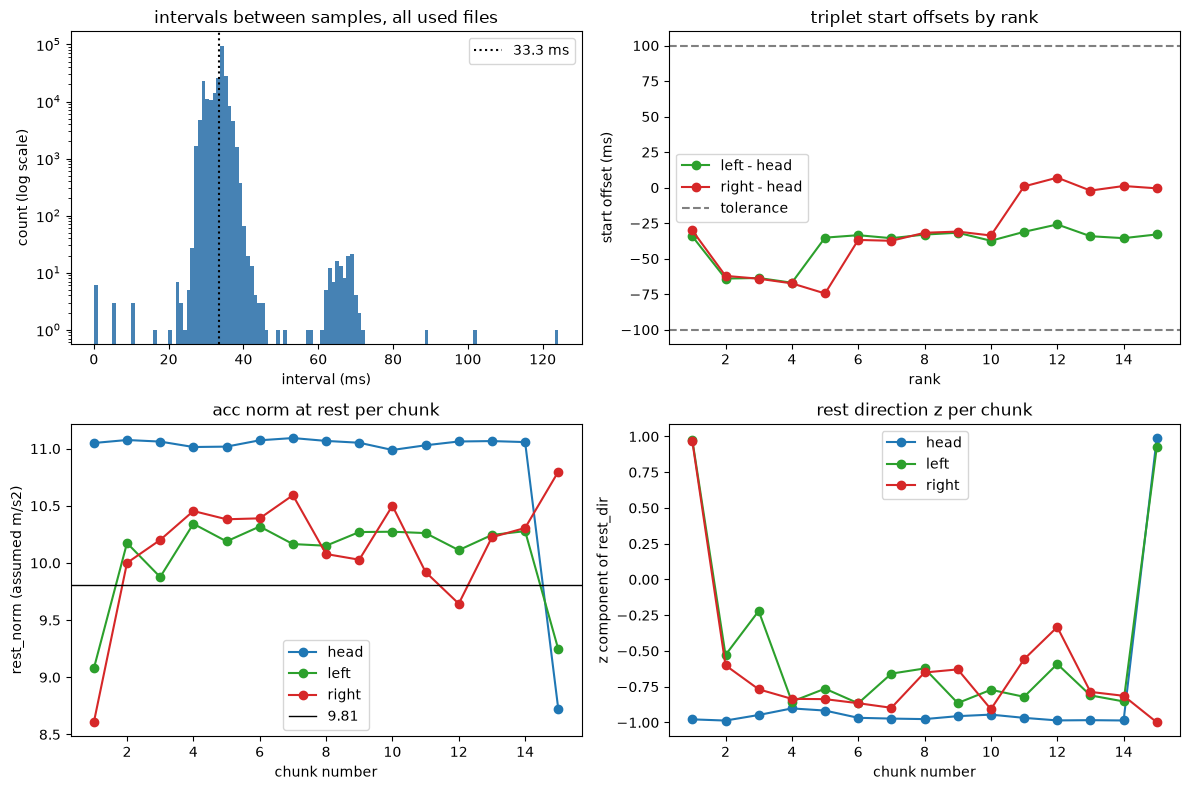

In [11]:
dev_color = {"head": "tab:blue", "left": "tab:green", "right": "tab:red"}
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# a: interval histogram
lo, hi = float(pooled["dt_ms"].min()), float(pooled["dt_ms"].max())
if hi <= lo:
    hi = lo + 1
bins = np.linspace(lo, hi, int(min(hi - lo, 300)) + 2)
axs[0, 0].hist(pooled["dt_ms"], bins=bins, color="steelblue")
axs[0, 0].set_yscale("log")
axs[0, 0].axvline(1000.0 / FPS, color="black", linestyle=":", label=f"{1000.0 / FPS:.1f} ms")
axs[0, 0].set_xlabel("interval (ms)")
axs[0, 0].set_ylabel("count (log scale)")
axs[0, 0].set_title("intervals between samples, all used files")
axs[0, 0].legend()

# b: triplet start offsets
axs[0, 1].plot(triplets["rank"], triplets["start_offset_left_ms"], "o-", color=dev_color["left"], label="left - head")
axs[0, 1].plot(triplets["rank"], triplets["start_offset_right_ms"], "o-", color=dev_color["right"], label="right - head")
axs[0, 1].axhline(TOL_MS, color="gray", linestyle="--")
axs[0, 1].axhline(-TOL_MS, color="gray", linestyle="--", label="tolerance")
axs[0, 1].set_xlabel("rank")
axs[0, 1].set_ylabel("start offset (ms)")
axs[0, 1].set_title("triplet start offsets by rank")
axs[0, 1].legend()

# c: rest norm
for d in DEVICES:
    g = chunks[chunks["device"] == d]
    axs[1, 0].plot(g["k"], g["rest_norm"], "o-", color=dev_color[d], label=d)
axs[1, 0].axhline(9.81, color="black", linewidth=1, label="9.81")
axs[1, 0].set_xlabel("chunk number")
axs[1, 0].set_ylabel("rest_norm (assumed m/s2)")
axs[1, 0].set_title("acc norm at rest per chunk")
axs[1, 0].ticklabel_format(axis="y", useOffset=False, style="plain")
axs[1, 0].legend()

# d: z of rest direction
for d in DEVICES:
    g = chunks[chunks["device"] == d]
    axs[1, 1].plot(g["k"], g["rest_dir_z"], "o-", color=dev_color[d], label=d)
axs[1, 1].set_xlabel("chunk number")
axs[1, 1].set_ylabel("z component of rest_dir")
axs[1, 1].set_title("rest direction z per chunk")
axs[1, 1].ticklabel_format(axis="y", useOffset=False, style="plain")
axs[1, 1].legend()

fig.tight_layout()
fig.savefig(REPORTS / "02_quality_panels.png", dpi=150)
plt.show()

## Step 11 - summary json

Collects the main numbers and the test results in one json file.

In [12]:
def clean(x):
    if isinstance(x, dict):
        return {str(k): clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [clean(v) for v in x]
    if isinstance(x, np.bool_):
        return bool(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating, float)):
        return float(x) if np.isfinite(x) else None
    if x is pd.NA:
        return None
    return x

rows_dev, dur_dev, first_dev, full_dev = {}, {}, {}, {}
for d in DEVICES:
    g = use[use["device"] == d].sort_values("clip_no")
    rows_dev[d] = int(g["rows"].sum())
    dur_dev[d] = float(g["duration_s"].sum() / 60.0)
    first_dev[d] = int(g["first_t_us"].iloc[0]) if len(g) else None
    full_dev[d] = int((g["rows"] == EXPECTED["chunk_rows"]).sum())

total_intervals = int((use["rows"] - 1).sum())
total_span = float(use["span_s"].sum())

summary_json = {
    "n_files": int(len(summary)),
    "n_stub": int((summary["status"] == "stub").sum()),
    "stub_files": quarantined,
    "rows_per_device": rows_dev,
    "duration_min_per_device": dur_dev,
    "first_t_us_per_device": first_dev,
    "overall_mean_rate_hz": total_intervals / total_span if total_span > 0 else None,
    "full_chunks_per_device": full_dev,
    "tests": hyp.to_dict(orient="records"),
    "run_timestamp_utc": datetime.now(timezone.utc).isoformat(),
}
with open(REPORTS / "02_summary.json", "w", encoding="utf-8") as fh:
    json.dump(clean(summary_json), fh, indent=2)
print("saved", REPORTS / "02_summary.json")
print("rows per device (used files):", rows_dev)

saved c:\workstation\3RD YEAR\ego_pipeline\reports\02_summary.json
rows per device (used files): {'head': 77371, 'left': 76254, 'right': 76882}


## Step 12 - zip for sharing

Puts the report files into one zip, without the npz files, and prints a short summary.

In [13]:
share_names = ["02_imu_file_summary.csv", "02_seams.csv", "02_file_time_check.csv",
               "02_triplet_offsets.csv", "02_dt_outliers.csv", "02_hypothesis_check.csv",
               "02_session_layout.png", "02_quality_panels.png", "02_summary.json"]
zip_path = REPORTS / "share_02.zip"
added = []
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for nm in share_names:
        p = REPORTS / nm
        if p.is_file():
            zf.write(p, arcname=nm)
            added.append(nm)
        else:
            print("missing, not added:", nm)

print("files parsed:", len(summary))
print("stubs found:", len(quarantined), quarantined)
for d in DEVICES:
    print(f"{d}: {rows_dev[d]} rows, {dur_dev[d]:.1f} min")
print("tests passed:", int((hyp["result"] == "PASS").sum()),
      " flagged:", int((hyp["result"] == "FLAG").sum()),
      " info:", int((hyp["result"] == "INFO").sum()))
flagged = hyp[hyp["result"] == "FLAG"]["id"].tolist()
if flagged:
    print("flagged tests:", flagged)
print("zip:", zip_path, f"({len(added)} files)")

files parsed: 47
stubs found: 2 ['a45140-H-0051', 'a59879-H-0041']
head: 77371 rows, 43.0 min
left: 76254 rows, 42.4 min
right: 76882 rows, 42.7 min
tests passed: 9  flagged: 1  info: 0
flagged tests: ['T8']
zip: c:\workstation\3RD YEAR\ego_pipeline\reports\share_02.zip (9 files)
